# Tree SHAP: interventional vs tree path dependent

[![open in colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ing-bank/probatus/blob/master/docs/discussion/nb_shap_feature_perturbation.ipynb)

SHAP can compute values for tree-based models in two ways, chosen with the `feature_perturbation` argument:

- **Interventional** (probatus' default): each sample is explained against a background sample of `sample_size` rows (100 by default) drawn from the data. A feature is "removed" by replacing its value with values from the background rows, which breaks its dependence on the other features.
- **Tree path dependent**: no background data is used. A feature is "removed" by following both branches of each split on it, weighted by how many training samples went each way. LightGBM, XGBoost and CatBoost compute this natively.

Tree path dependent is usually much faster, but the two approaches define feature removal differently, so the SHAP values differ. This notebook shows how large both effects are on one example: a single SHAP calculation, the feature importance ranking, and a full `ShapRFECV` run.

You can choose the faster option in every probatus class that computes SHAP values, by passing `feature_perturbation="tree_path_dependent"` to `fit` or `fit_compute`.

In [ ]:
%%capture
!pip install probatus
!pip install lightgbm

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from scipy.stats import spearmanr
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

from probatus.feature_elimination import ShapRFECV
from probatus.utils import calculate_shap_importance, shap_calc

feature_names = [f"f{i}" for i in range(30)]
X_array, y_array = make_classification(
    n_samples=2000,
    n_features=30,
    n_informative=8,
    n_redundant=8,
    class_sep=0.5,
    random_state=0,
)
X = pd.DataFrame(X_array, columns=feature_names)
y = pd.Series(y_array)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

# One thread per model: ShapRFECV below runs its cross-validation folds in parallel processes, and
# multithreaded LightGBM inside each of them would oversubscribe the CPU.
model = LGBMClassifier(n_estimators=100, max_depth=5, n_jobs=1, verbose=-1, random_state=0).fit(X_train, y_train)

## Speed of a single SHAP calculation

We explain the 1000 test rows with both approaches. Each calculation runs three times and the fastest run is kept. The timings in this notebook were measured on a 4-core machine; absolute numbers depend on your hardware, but the ratio is what matters.

In [2]:
def fastest_of_three(calculate):
    """Runs the calculation three times; returns the fastest time in seconds and the last result."""
    times = []
    for _ in range(3):
        start = time.perf_counter()
        result = calculate()
        times.append(time.perf_counter() - start)
    return min(times), result


time_interventional, shap_interventional = fastest_of_three(lambda: shap_calc(model, X_test, random_state=0))
time_path, shap_path = fastest_of_three(
    lambda: shap_calc(model, X_test, random_state=0, feature_perturbation="tree_path_dependent")
)

pd.DataFrame(
    {"seconds": [time_interventional, time_path]},
    index=["interventional (default)", "tree_path_dependent"],
).assign(speedup=lambda df: df["seconds"].iloc[0] / df["seconds"]).round(3)

,seconds,speedup
interventional (default),2.662,1.000
tree_path_dependent,0.083,31.908


## Difference in SHAP values

Both approaches split the same model output over the features: for every row, the SHAP values add up to the same prediction. They differ in how that output is attributed to individual features. The left plot compares every SHAP value (one point per row and feature); points on the diagonal are identical. The right plot compares each feature's mean absolute SHAP value, which is what probatus uses as feature importance.

Correlation of all SHAP values: 0.9900
Mean absolute difference, relative to the mean absolute SHAP value: 15.1%


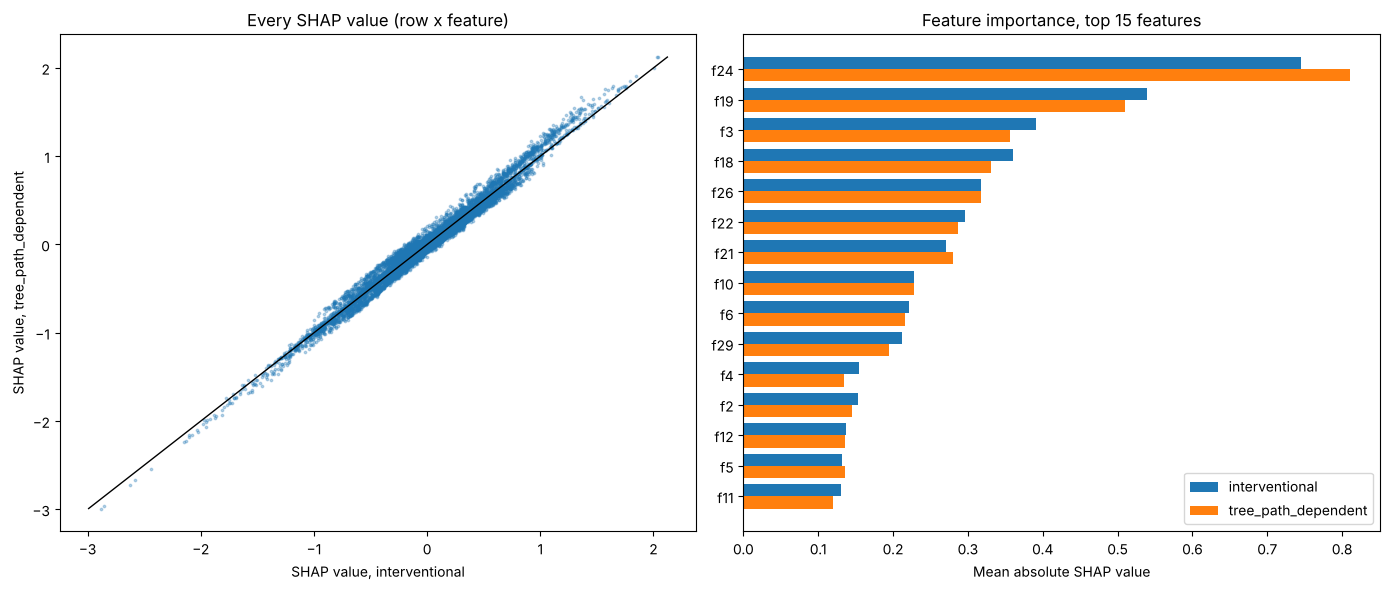

In [3]:
flat_interventional = shap_interventional.ravel()
flat_path = shap_path.ravel()
correlation = np.corrcoef(flat_interventional, flat_path)[0, 1]
relative_difference = np.abs(flat_interventional - flat_path).mean() / np.abs(flat_interventional).mean()
print(f"Correlation of all SHAP values: {correlation:.4f}")
print(f"Mean absolute difference, relative to the mean absolute SHAP value: {relative_difference:.1%}")

importance = pd.concat(
    [
        calculate_shap_importance(shap_interventional, feature_names, output_columns_suffix="_interventional"),
        calculate_shap_importance(shap_path, feature_names, output_columns_suffix="_path"),
    ],
    axis=1,
)[["mean_abs_shap_value_interventional", "mean_abs_shap_value_path"]]

fig, (ax_values, ax_importance) = plt.subplots(1, 2, figsize=(14, 6))
ax_values.scatter(flat_interventional, flat_path, s=3, alpha=0.3)
limits = [min(flat_interventional.min(), flat_path.min()), max(flat_interventional.max(), flat_path.max())]
ax_values.plot(limits, limits, color="black", linewidth=1)
ax_values.set_xlabel("SHAP value, interventional")
ax_values.set_ylabel("SHAP value, tree_path_dependent")
ax_values.set_title("Every SHAP value (row x feature)")

top_features = importance.sort_values("mean_abs_shap_value_interventional", ascending=False).head(15)
positions = np.arange(len(top_features))
ax_importance.barh(
    positions - 0.2, top_features["mean_abs_shap_value_interventional"], height=0.4, label="interventional"
)
ax_importance.barh(positions + 0.2, top_features["mean_abs_shap_value_path"], height=0.4, label="tree_path_dependent")
ax_importance.set_yticks(positions)
ax_importance.set_yticklabels(top_features.index)
ax_importance.invert_yaxis()
ax_importance.set_xlabel("Mean absolute SHAP value")
ax_importance.set_title("Feature importance, top 15 features")
ax_importance.legend()
plt.tight_layout()
plt.show()

Feature elimination removes the features with the lowest importance, so what matters most is whether the *ranking* changes. The table lists the features whose rank differs between the two approaches.

In [4]:
ranks = importance.rank(ascending=False).astype(int)
ranks.columns = ["rank_interventional", "rank_path"]
ranks["rank_change"] = ranks["rank_path"] - ranks["rank_interventional"]
ranks = ranks.sort_values("rank_interventional")

rank_correlation = spearmanr(ranks["rank_interventional"], ranks["rank_path"])[0]
print(f"Spearman correlation of the feature rankings: {rank_correlation:.3f}")
print(f"Features whose rank changes: {(ranks['rank_change'] != 0).sum()} of {len(ranks)}")
ranks[ranks["rank_change"] != 0]

Spearman correlation of the feature rankings: 0.994
Features whose rank changes: 12 of 30


,rank_interventional,rank_path,rank_change
f4,11,14,3
f2,12,11,-1
f12,13,12,-1
f5,14,13,-1
f11,15,16,1
f7,16,17,1
f15,17,15,-2
f1,20,21,1
f27,21,20,-1
f16,23,25,2


## Effect on feature elimination

`ShapRFECV` computes SHAP values in every cross-validation fold of every elimination round, so the speed difference adds up. Below we run the same elimination with both approaches and compare the run time, the validation score per number of features, and the selected features.

In [5]:
elimination_interventional = ShapRFECV(model, step=0.2, cv=5, scoring="roc_auc", n_jobs=-1, random_state=0)
start = time.perf_counter()
report_interventional = elimination_interventional.fit_compute(X_train, y_train)
rfe_time_interventional = time.perf_counter() - start

elimination_path = ShapRFECV(model, step=0.2, cv=5, scoring="roc_auc", n_jobs=-1, random_state=0)
start = time.perf_counter()
report_path = elimination_path.fit_compute(X_train, y_train, feature_perturbation="tree_path_dependent")
rfe_time_path = time.perf_counter() - start

pd.DataFrame(
    {"seconds": [rfe_time_interventional, rfe_time_path]},
    index=["interventional (default)", "tree_path_dependent"],
).assign(speedup=lambda df: df["seconds"].iloc[0] / df["seconds"]).round(1)

,seconds,speedup
interventional (default),19.2,1.0
tree_path_dependent,3.0,6.3


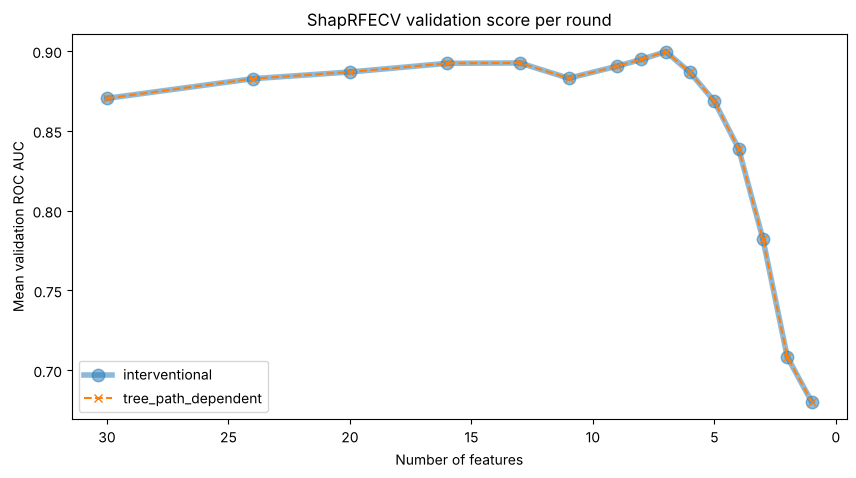

Rounds that evaluated the same feature set: 15 of 15
Best feature set, interventional:      7 features ['f3', 'f10', 'f18', 'f19', 'f22', 'f24', 'f26']
Best feature set, tree_path_dependent: 7 features ['f3', 'f10', 'f18', 'f19', 'f22', 'f24', 'f26']
Features in both sets: 7
Spearman correlation of the elimination order: 0.999


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    report_interventional["num_features"],
    report_interventional["val_metric_mean"],
    marker="o",
    markersize=9,
    linewidth=4,
    alpha=0.5,
    label="interventional",
)
ax.plot(
    report_path["num_features"], report_path["val_metric_mean"], marker="x", linestyle="--", label="tree_path_dependent"
)
ax.invert_xaxis()
ax.set_xlabel("Number of features")
ax.set_ylabel("Mean validation ROC AUC")
ax.set_title("ShapRFECV validation score per round")
ax.legend()
plt.show()

same_rounds = sum(
    set(features_interventional) == set(features_path)
    for features_interventional, features_path in zip(
        report_interventional["features_set"], report_path["features_set"]
    )
)
print(f"Rounds that evaluated the same feature set: {same_rounds} of {len(report_interventional)}")

best_interventional = elimination_interventional.get_reduced_features_set("best")
best_path = elimination_path.get_reduced_features_set("best")
print(f"Best feature set, interventional:      {len(best_interventional)} features {best_interventional}")
print(f"Best feature set, tree_path_dependent: {len(best_path)} features {best_path}")
print(f"Features in both sets: {len(set(best_interventional) & set(best_path))}")

ranking_correlation = spearmanr(
    elimination_interventional.get_reduced_features_set(1, return_type="ranking"),
    elimination_path.get_reduced_features_set(1, return_type="ranking"),
)[0]
print(f"Spearman correlation of the elimination order: {ranking_correlation:.3f}")

## Conclusion

- `tree_path_dependent` computes SHAP values for this LightGBM model many times faster than the default interventional approach, and the gap carries through to a full `ShapRFECV` run.
- The SHAP values themselves differ: both approaches attribute the same predictions, but split them over the features differently.
- The importance ranking, which feature elimination relies on, stays close. In this example the ten most important features keep their rank and the other changes move a feature by a few places. Both runs removed the same features in every round, so their validation curves coincide and they select the same best feature set. That is not guaranteed for every dataset: features with similar importance can swap places, and the elimination can then take a different path.

Use `feature_perturbation="tree_path_dependent"` when speed matters, for example with large data or many elimination rounds. Keep the default when you want the interventional definition of SHAP values, or results comparable with earlier runs.

The default interventional calculation runs in a single process. `ShapModelInterpreter`, `SHAPImportanceResemblance` and `DependencePlotter` accept `n_jobs` to spread it over several processes, with identical results. `ShapRFECV` already runs its cross-validation folds in parallel.